# Tensor-network block encoding for the nonlinear term

Goal: replace the dense `U_phi = block_encode(np.diag(sv_init))` of the main notebook by a gate sequence built from a **tensor train (TT)** of the field, as in the paper.

Pipeline: ansatz circuit U(θ) → TT of ψ (MPS simulation, "TTS") → diagonal TT-operator (delta tensors) → unitary gates (tensor programming) → block encoding of diag(ψ) with subnormalization `c`.

Sections 1–5 are pure NumPy (no Qiskit needed). Qiskit is used only in the cells marked *Qiskit*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 0. Library: TT, MPS simulation, canonical forms, diagonal operator

In [2]:
def ry_matrix(angle):
    c, s = np.cos(angle / 2), np.sin(angle / 2)
    return np.array([[c, -s], [s, c]])


def dense_ansatz_state(theta, n, n_layers):
    T = np.zeros((2,) * n)
    T[(0,) * n] = 1.0
    p = 0
    for layer in range(n_layers + 1):
        for q in range(n):
            T = np.moveaxis(np.tensordot(ry_matrix(theta[p]), T, axes=([1], [q])), 0, q)
            p += 1
        if layer < n_layers:
            for q in range(n - 1):
                index = [slice(None)] * n
                index[q] = 1
                T[tuple(index)] = np.flip(T[tuple(index)], axis=q)
    return T.transpose(list(range(n))[::-1]).reshape(-1)


def mps_zero(n):
    return [np.array([1.0, 0.0]).reshape(1, 2, 1) for _ in range(n)]


def mps_apply_1q(cores, q, gate):
    cores[q] = np.einsum("ij,ajb->aib", gate, cores[q])


def mps_move_center_left(cores):
    for k in range(len(cores) - 1, 0, -1):
        a, _, b = cores[k].shape
        Q, R = np.linalg.qr(cores[k].reshape(a, 2 * b).T)
        cores[k] = Q.T.reshape(Q.shape[1], 2, b)
        cores[k - 1] = np.einsum("aib,bc->aic", cores[k - 1], R.T)


def mps_apply_cx(cores, q, chi_max, tol=1e-14):
    pair = np.einsum("aib,bjc->aijc", cores[q], cores[q + 1])
    new = pair.copy()
    new[:, 1, :, :] = pair[:, 1, ::-1, :]
    a, _, _, c = new.shape
    U, S, Vh = np.linalg.svd(new.reshape(a * 2, 2 * c), full_matrices=False)
    keep = max(1, min(chi_max, int(np.sum(S > tol * S[0]))))
    U, S, Vh = U[:, :keep], S[:keep], Vh[:keep]
    cores[q] = U.reshape(a, 2, keep)
    cores[q + 1] = (np.diag(S) @ Vh).reshape(keep, 2, c)


def simulate_ansatz_mps(theta, n, n_layers, chi_max):
    cores = mps_zero(n)
    p = 0
    for layer in range(n_layers + 1):
        for q in range(n):
            mps_apply_1q(cores, q, ry_matrix(theta[p]))
            p += 1
        if layer < n_layers:
            mps_move_center_left(cores)
            for q in range(n - 1):
                mps_apply_cx(cores, q, chi_max)
    return cores


def tt_to_vector(cores):
    T = cores[0]
    for core in cores[1:]:
        T = np.tensordot(T, core, axes=([-1], [0]))
    T = T.reshape(T.shape[1:-1])
    return T.transpose(list(range(len(cores)))[::-1]).reshape(-1)


def vector_to_tt(vec, n, chi_max=None, tol=1e-14):
    rest = vec.reshape((2,) * n).transpose(list(range(n))[::-1]).reshape(1, -1)
    cores, r_prev = [], 1
    for k in range(n - 1):
        rest = rest.reshape(r_prev * 2, -1)
        U, S, Vh = np.linalg.svd(rest, full_matrices=False)
        keep = max(1, int(np.sum(S > tol * S[0])))
        if chi_max is not None:
            keep = min(keep, chi_max)
        U, S, Vh = U[:, :keep], S[:keep], Vh[:keep]
        cores.append(U.reshape(r_prev, 2, keep))
        rest = np.diag(S) @ Vh
        r_prev = keep
    cores.append(rest.reshape(r_prev, 2, 1))
    return cores


def tt_bond_dims(cores):
    return [core.shape[2] for core in cores[:-1]]


def tt_mixed_canonical(cores, center):
    cores = [c.copy() for c in cores]
    for k in range(center):
        a, _, b = cores[k].shape
        Q, R = np.linalg.qr(cores[k].reshape(a * 2, b))
        cores[k] = Q.reshape(a, 2, -1)
        cores[k + 1] = np.einsum("ab,bic->aic", R, cores[k + 1])
    for k in range(len(cores) - 1, center, -1):
        a, _, b = cores[k].shape
        Q, R = np.linalg.qr(cores[k].reshape(a, 2 * b).T)
        cores[k] = Q.T.reshape(-1, 2, b)
        cores[k - 1] = np.einsum("aib,bc->aic", cores[k - 1], R.T)
    return cores


def tt_to_diagonal_tto(cores):
    W = []
    for core in cores:
        a, _, b = core.shape
        w = np.zeros((a, 2, 2, b))
        w[:, 0, 0, :] = core[:, 0, :]
        w[:, 1, 1, :] = core[:, 1, :]
        W.append(w)
    return W


def tto_to_dense(W):
    n = len(W)
    T = W[0]
    for w in W[1:]:
        T = np.tensordot(T, w, axes=([-1], [0]))
    T = T.reshape(T.shape[1:-1])
    out_axes = list(range(0, 2 * n, 2))[::-1]
    in_axes = list(range(1, 2 * n, 2))[::-1]
    return T.transpose(out_axes + in_axes).reshape(2 ** n, 2 ** n)

## Compiler: diagonal TT-operator → unitary gates

For every site `k` and every value `i` of data qubit `k`, the bond matrix `M_k^(i) = W_k[:, i, i, :]^T / c_k` (a contraction, `c_k` = largest spectral norm over `i`) is dilated to a unitary acting on a **bond register** (`ceil(log2 chi)` qubits, reused by all sites) and one **flag qubit per site**. It is applied controlled on data qubit `k` being `i`.

Post-selecting bond register and flags on `|0>` gives `<0|U|0> = diag(psi) / c`, with `c = prod_k c_k`.
Qubit order: data qubits `0..n-1`, then bond register, then flags.

In [3]:
def matrix_sqrt_psd(H):
    eigvals, eigvecs = np.linalg.eigh((H + H.conj().T) / 2)
    return (eigvecs * np.sqrt(np.clip(eigvals, 0, None))) @ eigvecs.conj().T


def dilate(A):
    I = np.eye(A.shape[0])
    return np.block([[A, matrix_sqrt_psd(I - A @ A.conj().T)],
                     [matrix_sqrt_psd(I - A.conj().T @ A), -A.conj().T]])


def site_scale(w):
    return max(np.linalg.norm(w[:, i, i, :], 2) for i in range(2)) * (1 + 1e-6)


def diagonal_tto_scale(W):
    return float(np.prod([site_scale(w) for w in W]))


def best_canonical_center(cores):
    best = None
    for center in range(len(cores)):
        trial = tt_mixed_canonical(cores, center)
        scale = diagonal_tto_scale(tt_to_diagonal_tto(trial))
        if best is None or scale < best[0]:
            best = (scale, center, trial)
    return best[2], best[1], best[0]


def compile_diagonal_tto(W):
    n = len(W)
    max_bond = max(max(w.shape[0], w.shape[3]) for w in W)
    n_bond = max(1, int(np.ceil(np.log2(max_bond))))
    bond_qubits = list(range(n, n + n_bond))
    flag_qubits = list(range(n + n_bond, 2 * n + n_bond))
    dim_bond = 2 ** n_bond
    ops, scale = [], 1.0
    for k, w in enumerate(W):
        c_k = site_scale(w)
        if c_k == 0:
            c_k = 1.0
        scale *= c_k
        for i in range(2):
            A = np.zeros((dim_bond, dim_bond))
            block = w[:, i, i, :].T / c_k
            A[:block.shape[0], :block.shape[1]] = block
            ops.append(dict(matrix=dilate(A), targets=bond_qubits + [flag_qubits[k]],
                            control=k, ctrl_state=i))
    return dict(ops=ops, n_data=n, n_aux=n_bond + n, n_qubits=2 * n + n_bond, scale=scale,
                bond_qubits=bond_qubits, flag_qubits=flag_qubits)


def compile_from_cores(cores):
    cores, center, _ = best_canonical_center(cores)
    return compile_diagonal_tto(tt_to_diagonal_tto(cores))


def op_to_dense(op, n_qubits):
    dim = 2 ** n_qubits
    F = np.zeros((dim, dim), dtype=complex)
    targets = op["targets"]
    for s in range(dim):
        if ((s >> op["control"]) & 1) != op["ctrl_state"]:
            F[s, s] = 1.0
            continue
        j = sum(((s >> q) & 1) << pos for pos, q in enumerate(targets))
        base = s
        for q in targets:
            base &= ~(1 << q)
        for jp in range(2 ** len(targets)):
            sp = base
            for pos, q in enumerate(targets):
                sp |= ((jp >> pos) & 1) << q
            F[sp, s] = op["matrix"][jp, j]
    return F


def compiled_to_dense(compiled):
    U = np.eye(2 ** compiled["n_qubits"], dtype=complex)
    for op in compiled["ops"]:
        U = op_to_dense(op, compiled["n_qubits"]) @ U
    return U

## 1. TT of the state from the circuit (tensor-train simulation, TTS)

The ansatz is simulated as an MPS with maximum bond dimension `chi_max`. The `2^n` statevector is never formed.

In [4]:
n = 3
n_layers = 5
rng_demo = np.random.default_rng(0)
theta_demo = rng_demo.uniform(0, 2 * np.pi, n * (n_layers + 1))

psi_dense = dense_ansatz_state(theta_demo, n, n_layers)
cores_tts = simulate_ansatz_mps(theta_demo, n, n_layers, chi_max=64)

print("bond dimensions:", tt_bond_dims(cores_tts))
print("TTS vs dense statevector, max error:", np.max(np.abs(tt_to_vector(cores_tts) - psi_dense)))

bond dimensions: [2, 2]
TTS vs dense statevector, max error: 7.216449660063518e-16


In [5]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator


def qiskit_ansatz(n, n_layers):
    theta = ParameterVector("θ", n * (n_layers + 1))
    circuit = QuantumCircuit(n)
    p = 0
    for layer in range(n_layers + 1):
        for q in range(n):
            circuit.ry(theta[p], q)
            p += 1
        if layer < n_layers:
            for q in range(n - 1):
                circuit.cx(q, q + 1)
    return circuit, theta


qc_check, theta_check = qiskit_ansatz(n, n_layers)
sv_qiskit = Statevector(qc_check.assign_parameters({theta_check: theta_demo})).data.real
print("numpy ansatz vs Qiskit statevector, max error:", np.max(np.abs(sv_qiskit - psi_dense)))
assert np.allclose(sv_qiskit, psi_dense, atol=1e-10)

numpy ansatz vs Qiskit statevector, max error: 0.0


chi_max=  2   infidelity=9.08e-01
chi_max=  4   infidelity=5.05e-01
chi_max=  8   infidelity=8.50e-02
chi_max= 16   infidelity=2.35e-06
chi_max= 32   infidelity=8.88e-16
chi_max= 64   infidelity=8.88e-16


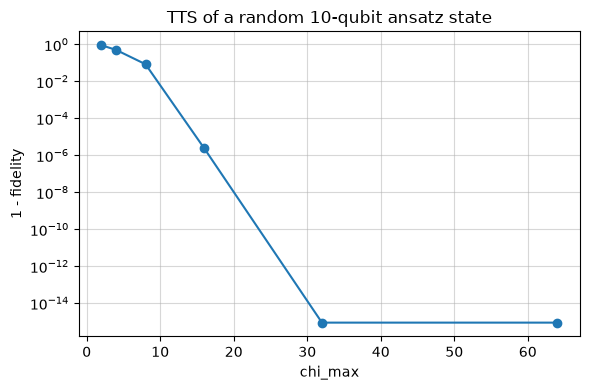

In [6]:
n_big, chi_list = 10, [2, 4, 8, 16, 32, 64]
theta_big = np.random.default_rng(1).uniform(0, 2 * np.pi, n_big * (n_layers + 1))
psi_big = dense_ansatz_state(theta_big, n_big, n_layers)

infidelity = []
for chi in chi_list:
    v = tt_to_vector(simulate_ansatz_mps(theta_big, n_big, n_layers, chi))
    v = v / np.linalg.norm(v)
    infidelity.append(max(1 - abs(v @ psi_big) ** 2, 1e-16))
    print(f"chi_max={chi:3d}   infidelity={infidelity[-1]:.2e}")

plt.figure(figsize=(6, 4))
plt.semilogy(chi_list, infidelity, "o-")
plt.xlabel("chi_max"); plt.ylabel("1 - fidelity"); plt.grid(alpha=0.5)
plt.title(f"TTS of a random {n_big}-qubit ansatz state")
plt.tight_layout(); plt.show()

## 2. TT → diagonal TT-operator (delta tensors)

In [7]:
W_demo = tt_to_diagonal_tto(cores_tts)
print("TTO core shapes:", [w.shape for w in W_demo])
print("TTO vs diag(psi), max error:", np.max(np.abs(tto_to_dense(W_demo) - np.diag(psi_dense))))

TTO core shapes: [(1, 2, 2, 2), (2, 2, 2, 2), (2, 2, 2, 1)]
TTO vs diag(psi), max error: 7.216449660063518e-16


## 3. Compile to gates and verify the block encoding (NumPy)

In [8]:
compiled = compile_from_cores(cores_tts)
U_tn = compiled_to_dense(compiled)
N_demo = 2 ** n

print("qubits:", compiled["n_qubits"], " aux qubits:", compiled["n_aux"], " controlled gates:", len(compiled["ops"]))
print("unitarity error:", np.max(np.abs(U_tn.conj().T @ U_tn - np.eye(U_tn.shape[0]))))
print("block error vs diag(psi):", np.max(np.abs(U_tn[:N_demo, :N_demo] * compiled["scale"] - np.diag(psi_dense))))
print(f"scale c_TT = {compiled['scale']:.4f}   max|psi| = {np.max(np.abs(psi_dense)):.4f}")

qubits: 7  aux qubits: 4  controlled gates: 6
unitarity error: 1.8019292822491128e-14
block error vs diag(psi): 7.771561172376096e-16
scale c_TT = 0.8371   max|psi| = 0.7716


Qiskit operator vs NumPy assembly: 1.1310758291169791e-14
Qiskit block vs diag(psi): 3.554804970525823e-15


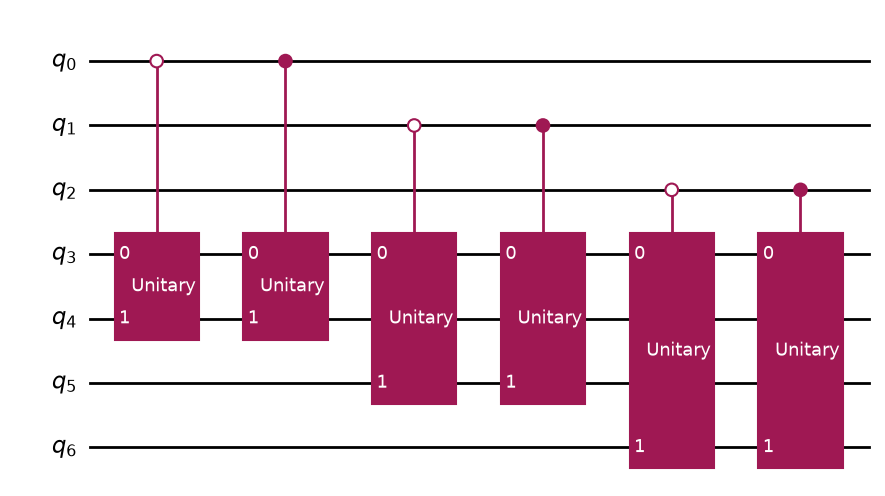

In [9]:
def ops_to_circuit(compiled):
    circuit = QuantumCircuit(compiled["n_qubits"])
    for op in compiled["ops"]:
        gate = UnitaryGate(op["matrix"]).control(1, ctrl_state=op["ctrl_state"])
        circuit.append(gate, [op["control"]] + op["targets"])
    return circuit


circuit_tn = ops_to_circuit(compiled)
U_qiskit = Operator(circuit_tn).data
print("Qiskit operator vs NumPy assembly:", np.max(np.abs(U_qiskit - U_tn)))
print("Qiskit block vs diag(psi):", np.max(np.abs(U_qiskit[:N_demo, :N_demo] * compiled["scale"] - np.diag(psi_dense))))
assert np.allclose(U_qiskit, U_tn, atol=1e-8)
assert np.allclose(U_qiskit[:N_demo, :N_demo] * compiled["scale"], np.diag(psi_dense), atol=1e-8)
circuit_tn.draw("mpl", fold=-1)

## 4. Subnormalization: `c_TT` versus the ideal `max|psi|`

The success probability scales like `1/c^2`, so `c_TT / max|psi|` is the price of building the encoding from a TT.

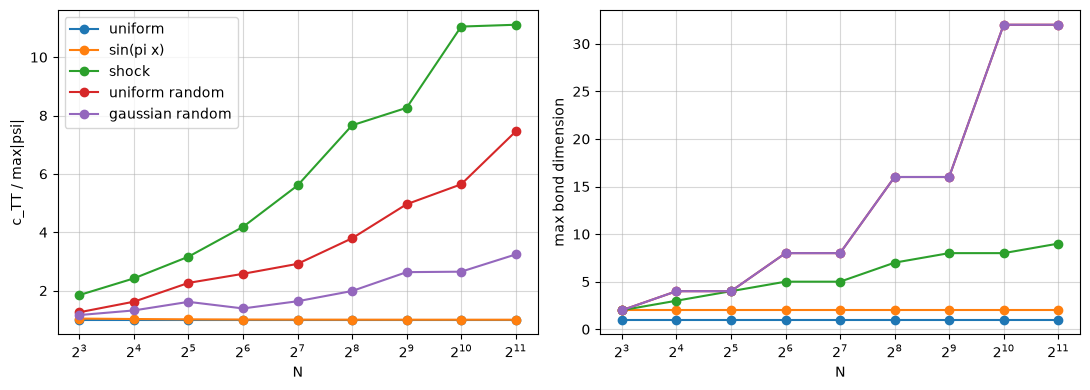

In [10]:
def test_field(kind, N, rng):
    xs = np.linspace(0, 1, N)
    if kind == "uniform":
        f = np.ones(N)
    elif kind == "sin(pi x)":
        f = np.sin(np.pi * xs)
    elif kind == "shock":
        f = -np.tanh((xs - 0.5) / 0.02)
    elif kind == "uniform random":
        f = rng.uniform(0, 1, N)
    else:
        f = rng.standard_normal(N)
    return f / np.linalg.norm(f)


kinds = ["uniform", "sin(pi x)", "shock", "uniform random", "gaussian random"]
n_list = np.arange(3, 12)
rng_fields = np.random.default_rng(5)
ratio = {k: [] for k in kinds}
chi = {k: [] for k in kinds}

for kind in kinds:
    for n_q in n_list:
        psi_f = test_field(kind, 2 ** n_q, rng_fields)
        cores_f = vector_to_tt(psi_f, n_q, tol=1e-10)
        _, _, scale_f = best_canonical_center(cores_f)
        ratio[kind].append(scale_f / np.max(np.abs(psi_f)))
        chi[kind].append(max(tt_bond_dims(cores_f)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for kind in kinds:
    ax[0].plot(2 ** n_list, ratio[kind], "o-", label=kind)
    ax[1].plot(2 ** n_list, chi[kind], "o-", label=kind)
ax[0].set_xscale("log", base=2); ax[1].set_xscale("log", base=2)
ax[0].set_xlabel("N"); ax[0].set_ylabel("c_TT / max|psi|"); ax[0].grid(alpha=0.5); ax[0].legend()
ax[1].set_xlabel("N"); ax[1].set_ylabel("max bond dimension"); ax[1].grid(alpha=0.5)
plt.tight_layout(); plt.show()

## 5. Success probability of one Burgers Euler step versus N (paper Fig. 2 idea)

Same operator `O_full`, three subnormalizations for the diagonal field: state-based (`c = ||u||_2`), ideal block-diagonal (`c = max|u|`), and the TT-compiled one.

As in the paper (Appendix C) the step size follows `max|u| dt/dx = 0.5` and the viscosity is small, so the nonlinear term carries real weight. With the diffusion-limited `dt ~ dx^2` of the main notebook the linear identity part dominates and the effect is hidden. Only one step is evaluated, so stability of repeated stepping is not an issue here.

N=8 ideal block-diagonal alpha: 0.4799143925944918


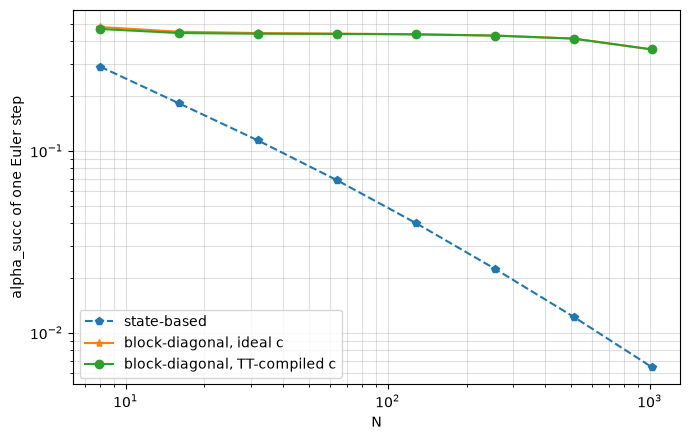

In [11]:
def burgers_setup(n_q, nu=1e-3, length=1.0, cfl=0.5):
    N = 2 ** n_q
    x = np.linspace(0, length, N)
    dx = x[1] - x[0]
    dt = cfl * dx
    D1 = (np.diag(np.ones(N - 1), 1) - np.diag(np.ones(N - 1), -1)) / (2 * dx)
    D2 = (np.diag(np.ones(N - 1), 1) + np.diag(np.ones(N - 1), -1) - 2 * np.eye(N)) / dx ** 2
    for D in (D1, D2):
        D[0], D[-1] = 0.0, 0.0
    return x, dt, nu, D1, D2


def step_alpha(psi, norm_u, dt, nu, D1, D2, c_diag):
    N = len(psi)
    c_L = np.linalg.norm(np.eye(N) + dt * nu * D2, 2) * (1 + 1e-6)
    c_C = np.linalg.norm(dt * D1, 2) * (1 + 1e-6)
    beta_full = c_L + c_C * c_diag * norm_u
    out = psi + dt * nu * (D2 @ psi) - dt * norm_u * psi * (D1 @ psi)
    return np.linalg.norm(out) ** 2 / beta_full ** 2


alpha_state, alpha_ideal, alpha_tn = [], [], []
n_alpha = np.arange(3, 11)
for n_q in n_alpha:
    x_a, dt_a, nu_a, D1_a, D2_a = burgers_setup(n_q)
    u0 = np.sin(np.pi * x_a)
    u0[0] = u0[-1] = 0.0
    norm_u = np.linalg.norm(u0)
    psi_a = u0 / norm_u
    _, _, c_tn = best_canonical_center(vector_to_tt(psi_a, n_q, tol=1e-10))
    alpha_state.append(step_alpha(psi_a, norm_u, dt_a, nu_a, D1_a, D2_a, 1.0))
    alpha_ideal.append(step_alpha(psi_a, norm_u, dt_a, nu_a, D1_a, D2_a, np.max(np.abs(psi_a)) * (1 + 1e-6)))
    alpha_tn.append(step_alpha(psi_a, norm_u, dt_a, nu_a, D1_a, D2_a, c_tn))

print("N=8 ideal block-diagonal alpha:", alpha_ideal[0])

plt.figure(figsize=(7, 4.5))
plt.loglog(2 ** n_alpha, alpha_state, "p--", label="state-based")
plt.loglog(2 ** n_alpha, alpha_ideal, "*-", label="block-diagonal, ideal c")
plt.loglog(2 ** n_alpha, alpha_tn, "o-", label="block-diagonal, TT-compiled c")
plt.xlabel("N"); plt.ylabel("alpha_succ of one Euler step"); plt.grid(alpha=0.4, which="both"); plt.legend()
plt.tight_layout(); plt.savefig("alpha_step_vs_N.png", dpi=150); plt.show()

## 6. Resource table for the compiled `U_phi` (Burgers initial field)

In [12]:
print(f"{'N':>6} {'chi':>4} {'aux qubits':>10} {'total qubits':>12} {'ctrl gates':>10} {'c_TT/max|psi|':>14}")
for n_q in range(3, 13):
    x_r = np.linspace(0, 1, 2 ** n_q)
    u_r = np.sin(np.pi * x_r)
    psi_r = u_r / np.linalg.norm(u_r)
    cores_r, _, scale_r = best_canonical_center(vector_to_tt(psi_r, n_q, tol=1e-10))
    chi_r = max(tt_bond_dims(cores_r))
    n_bond_r = max(1, int(np.ceil(np.log2(chi_r))))
    print(f"{2 ** n_q:>6} {chi_r:>4} {n_bond_r + n_q:>10} {2 * n_q + n_bond_r:>12} {2 * n_q:>10} {scale_r / np.max(np.abs(psi_r)):>14.3f}")

     N  chi aux qubits total qubits ctrl gates  c_TT/max|psi|
     8    2          4            7          6          1.040
    16    2          5            9          8          1.025
    32    2          6           11         10          1.014
    64    2          7           13         12          1.007
   128    2          8           15         14          1.004
   256    2          9           17         16          1.002
   512    2         10           19         18          1.001
  1024    2         11           21         20          1.000
  2048    2         12           23         22          1.000
  4096    2         13           25         24          1.000


## 7. Plug-in for the main notebook

`build_U_phi_gate` returns a gate on `[data qubits] + [aux qubits]` and the subnormalization `c`. In the main notebook this replaces `U_phi, c_D = block_encode(np.diag(sv_init), "U_phi")`:

- `A2` becomes a list of `n_aux` qubits and the register map grows accordingly,
- the post-selection mask `keep` also requires all `A2` qubits to be 0,
- `c_D` is `compiled["scale"]`.

In [13]:
def build_U_phi_gate(cores):
    compiled = compile_from_cores(cores)
    gate = ops_to_circuit(compiled).to_gate(label="U_phi_TN")
    return gate, compiled["scale"], compiled["n_aux"], compiled


gate_demo, c_demo, n_aux_demo, _ = build_U_phi_gate(simulate_ansatz_mps(theta_demo, n, n_layers, chi_max=8))
print("gate qubits:", gate_demo.num_qubits, " n_aux:", n_aux_demo, " c:", c_demo)

gate qubits: 7  n_aux: 4  c: 0.8370827338232716
